# MINI PROJECT: MUSIC RECOMMENDATION USING KNN, K-MEANS AND HIERARCHICAL CLUSTERING

In [1]:
dev_by = "Ashish Umrao (4315), Abhijeet Kumar (4301), and Aryan Singh (4313)"
checked_by = "Prof. Vaishali Ingle"
print("Developed by: " + dev_by + "\nChecked by: " + checked_by)

Developed by: Ashish Umrao (4315), Abhijeet Kumar (4301), and Aryan Singh (4313)
Checked by: Prof. Vaishali Ingle


## 1. PROBLEM DEFINITION

Music streaming apps contain millions of songs, so a listener cannot search through all of them manually.
A **recommendation system** helps the listener by suggesting new songs that are similar to a song they already like.

**Objective:** Build a **content-based music recommendation system** that, given one song, recommends the
**10 most similar songs** using the song's genre and audio features (danceability, energy, loudness, acousticness, tempo, etc.).

**Approach:** The project compares KNN, K-Means and Ward hierarchical clustering for content-based recommendations (PR7 and PR9).

- Every song is represented as a point in feature space.
- Songs that are *close* to each other in this space *sound* similar.
- **Recommendation:** `NearestNeighbors` retrieves the nearest songs by distance over scaled audio features plus one-hot genre. It is a search method, not a classifier or a clustering algorithm.
- **Genre classification:** `KNeighborsClassifier` predicts genre from audio features only. Genre is excluded from classification inputs to avoid including the target answer. Classification metrics apply only to KNN. Cluster numbers are arbitrary and are not genre predictions.
- **Clustering:** K-Means groups songs around centroids; hierarchical clustering builds a hierarchy of groups. Recommendations are the closest songs inside the selected cluster.
- **Evaluation:** classification uses Accuracy, Precision, Recall, F1-Score and Confusion Matrix; recommendation quality uses **Precision@10**, the fraction of the 10 recommendations sharing the input song's genre.
- **Optimization:** Cross Validation and `GridSearchCV` tune KNN neighbor count and voting weights; Euclidean distance is fixed throughout. An elbow plot and dendrogram support choosing the number of clusters; no test songs are used to fit clusters.

**Dimensionality reduction (PR10):** compare KNN before and after PCA, alongside KNN training and evaluation.

### PEAS Representation of the Recommendation Agent

| PEAS Component | Music Recommendation System |
|---|---|
| **Performance Measure** | Accuracy, Precision, Recall, F1-Score of genre prediction; Precision@10 of recommendations (same-genre songs) |
| **Environment** | Song catalogue (Spotify Tracks Dataset) and a user selecting a song in the notebook or desktop app |
| **Actuators** | Displaying the top-10 recommended songs and model evaluation results |
| **Sensors** | The song name entered by the user and that song's audio features from the dataset |

**Genre encoding:** use one binary column per genre for recommendation. Equal audio features in different genres have an added Euclidean distance of √2. Genre classification excludes these columns to avoid target leakage.


## 2. DATASET COLLECTION

**Dataset:** Spotify Tracks Dataset (114,000 songs, 114 genres, 1,000 songs per genre).

- Hugging Face: https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset
- Kaggle: search "Spotify Tracks Dataset" by Maharshi Pandya (same `dataset.csv` file)

Download `dataset.csv` and keep it in the same folder as this notebook.

#### IMPORTING LIBRARIES

In [2]:
# pandas: tables; NumPy: arrays; Matplotlib and Seaborn: graphs.
# LabelEncoder converts text categories into numbers.
# MinMaxScaler puts all features in the range 0 to 1.
# KNeighborsClassifier predicts genre; NearestNeighbors finds similar songs.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, GridSearchCV

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

# Reuse the same sklearn clustering and evaluation code as the Streamlit app.
import sys
from pathlib import Path
from dataclasses import replace
from scipy.cluster.hierarchy import dendrogram
sys.path.insert(0, str(Path("music_recommender_gui/src").resolve()))
from music_recommender.core.clustering import ClusterRecommender, compare_recommenders
from sklearn.decomposition import PCA


#### LOADING DATASET

In [3]:
df = pd.read_csv("dataset.csv")

## Printing number of samples and features in our dataset.
print("Number of samples: ", df.shape[0])
print("Number of features: ", df.shape[1])

Number of samples:  114000
Number of features:  21


In [4]:
## PRINTING TOP 5 SAMPLES OF OUR DATASET.
df.head(5)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [5]:
## Printing feature name alongwith its total values present and its data type
for col in df.columns:
    print(f'feature Name = "{col}",' , f'Total Values Present = {df[col].count()},',  f'Data Type = {df[col].dtype}')

feature Name = "Unnamed: 0", Total Values Present = 114000, Data Type = int64
feature Name = "track_id", Total Values Present = 114000, Data Type = str
feature Name = "artists", Total Values Present = 113999, Data Type = str
feature Name = "album_name", Total Values Present = 113999, Data Type = str
feature Name = "track_name", Total Values Present = 113999, Data Type = str
feature Name = "popularity", Total Values Present = 114000, Data Type = int64
feature Name = "duration_ms", Total Values Present = 114000, Data Type = int64
feature Name = "explicit", Total Values Present = 114000, Data Type = bool
feature Name = "danceability", Total Values Present = 114000, Data Type = float64
feature Name = "energy", Total Values Present = 114000, Data Type = float64
feature Name = "key", Total Values Present = 114000, Data Type = int64
feature Name = "loudness", Total Values Present = 114000, Data Type = float64
feature Name = "mode", Total Values Present = 114000, Data Type = int64
feature Name

In [6]:
## Number of genres present in the dataset
print("Number of genres:", df["track_genre"].nunique())
print("\nSongs per genre (first 10):")
print(df["track_genre"].value_counts().head(10))

Number of genres: 114

Songs per genre (first 10):
track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64


## 3. DATA PREPROCESSING

#### DATA CLEANING

In [7]:
## "Unnamed: 0" is only a row number, so it is not useful. Dropping this column.
df.drop(columns=["Unnamed: 0"], inplace=True)

#### Detect Missing Values

In [8]:
for col in df.columns:
    print(f"Column Name      : {col}")
    print(f"Missing Values   : {df[col].isnull().sum()}")
    print("-" * 35)

Column Name      : track_id
Missing Values   : 0
-----------------------------------
Column Name      : artists
Missing Values   : 1
-----------------------------------
Column Name      : album_name
Missing Values   : 1
-----------------------------------
Column Name      : track_name
Missing Values   : 1
-----------------------------------
Column Name      : popularity
Missing Values   : 0
-----------------------------------
Column Name      : duration_ms
Missing Values   : 0
-----------------------------------
Column Name      : explicit
Missing Values   : 0
-----------------------------------
Column Name      : danceability
Missing Values   : 0
-----------------------------------
Column Name      : energy
Missing Values   : 0
-----------------------------------
Column Name      : key
Missing Values   : 0
-----------------------------------
Column Name      : loudness
Missing Values   : 0
-----------------------------------
Column Name      : mode
Missing Values   : 0
---------------

#### HANDLING MISSING VALUES

In [9]:
# Only one song has missing artist / album / track name.
# A song without a name cannot be recommended, so that row is removed.
df.dropna(inplace=True)

print("Missing values after handling:", df.isnull().sum().sum())
print("Number of samples:", df.shape[0])

Missing values after handling: 0
Number of samples: 113999


#### SELECTING SEVEN GENRES

Use the previous seven genres: classical, hip-hop, heavy-metal, EDM, jazz, country and pop.
Genre remains a one-hot recommendation input. Selecting this smaller catalogue makes
training and classification diagnostics quicker. The selection can still be changed.

In [10]:
selected_genres = ["classical", "hip-hop", "heavy-metal", "edm", "jazz", "country", "pop"]
df = df[df["track_genre"].isin(selected_genres)].reset_index(drop=True)
print("Selected genres:", selected_genres)
print("Number of samples:", len(df))
print(df["track_genre"].value_counts())

Selected genres: ['classical', 'hip-hop', 'heavy-metal', 'edm', 'jazz', 'country', 'pop']
Number of samples: 7000
track_genre
classical      1000
country        1000
edm            1000
heavy-metal    1000
hip-hop        1000
jazz           1000
pop            1000
Name: count, dtype: int64


#### HANDLING DUPLICATE SONGS

In [11]:
# 1. The same track_id can appear under more than one genre.
# 2. The same song (same name and artist) can appear on different albums with a different track_id.
# Keeping duplicates would make the system recommend the same song again, so we keep only the first copy.
print("Duplicate track_id:", df.duplicated(subset="track_id").sum())
df = df.drop_duplicates(subset="track_id")

print("Duplicate songs (same name and artist):", df.duplicated(subset=["track_name", "artists"]).sum())
df = df.drop_duplicates(subset=["track_name", "artists"]).reset_index(drop=True)

print("\nNumber of samples after removing duplicates:", df.shape[0])

Duplicate track_id: 255
Duplicate songs (same name and artist): 1820

Number of samples after removing duplicates: 4925


#### STATISTICAL ANALYSIS

In [12]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,4925.000000,4.925000e+03,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000
mean,34.433096,2.253500e+05,0.544904,0.604030,5.338883,-8.995889,0.625584,0.074575,0.352922,0.138003,0.197743,0.456741,119.460469,3.890355
std,28.617676,1.153140e+05,0.173157,0.280835,3.534310,6.516121,0.484021,0.070954,0.368777,0.301409,0.168785,0.227343,29.854606,0.446757
min,0.000000,1.745300e+04,0.000000,0.000756,0.000000,-41.531000,0.000000,0.000000,0.000002,0.000000,0.021100,0.000000,0.000000,0.000000
25%,1.000000,1.745080e+05,0.425000,0.417000,2.000000,-10.229000,0.000000,0.036000,0.016000,0.000000,0.097800,0.279000,95.983000,4.000000
50%,30.000000,2.105330e+05,0.548000,0.660000,5.000000,-6.695000,1.000000,0.047900,0.184000,0.000021,0.129000,0.448000,119.800000,4.000000
75%,63.000000,2.546930e+05,0.676000,0.835000,9.000000,-4.872000,1.000000,0.079900,0.713000,0.012900,0.245000,0.622000,139.933000,4.000000
max,100.000000,2.646866e+06,0.964000,0.998000,11.000000,0.366000,1.000000,0.905000,0.996000,0.984000,0.986000,0.979000,214.016000,5.000000


#### DATA VISUALISATION

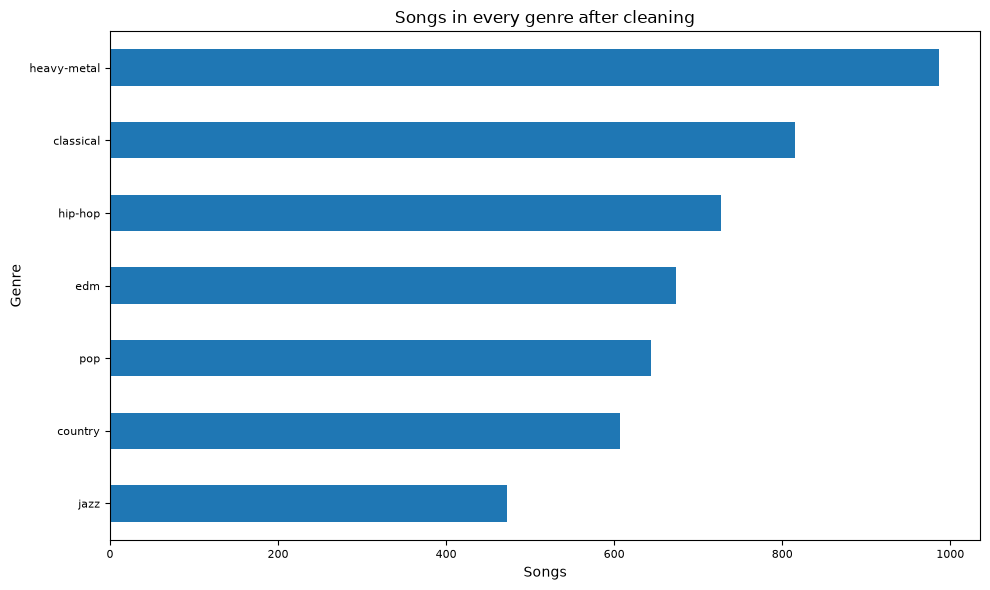

In [13]:
counts = df["track_genre"].value_counts().sort_values()
counts.plot.barh(figsize=(10, max(6, len(counts) * 0.19)), fontsize=8)
plt.title("Songs in every genre after cleaning")
plt.xlabel("Songs")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

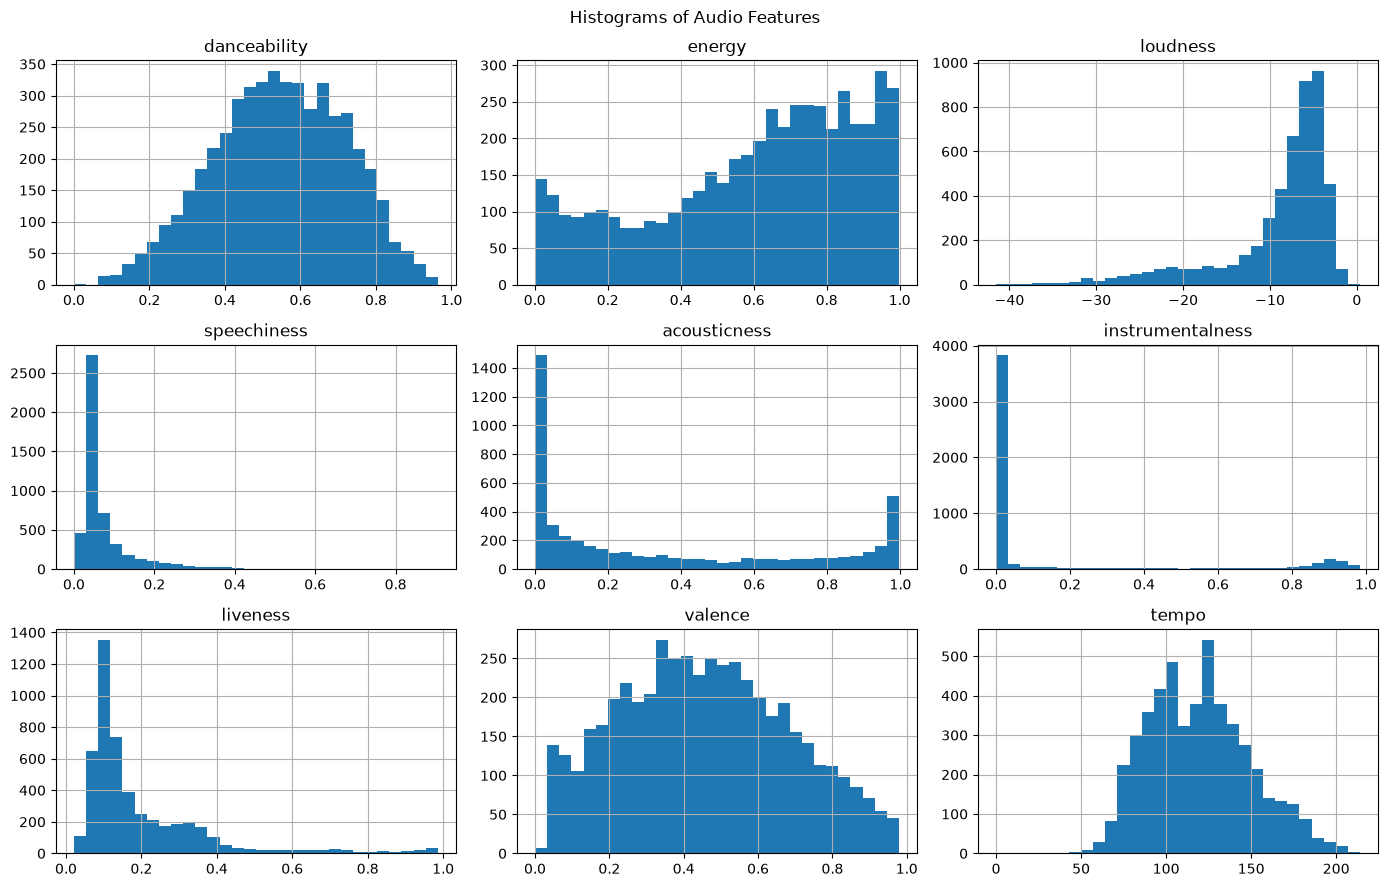

In [14]:
# Histograms show the distribution of each audio feature.
audio_features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo"]

df[audio_features].hist(figsize=(14, 9), bins=30)
plt.suptitle("Histograms of Audio Features")
plt.tight_layout()
plt.show()

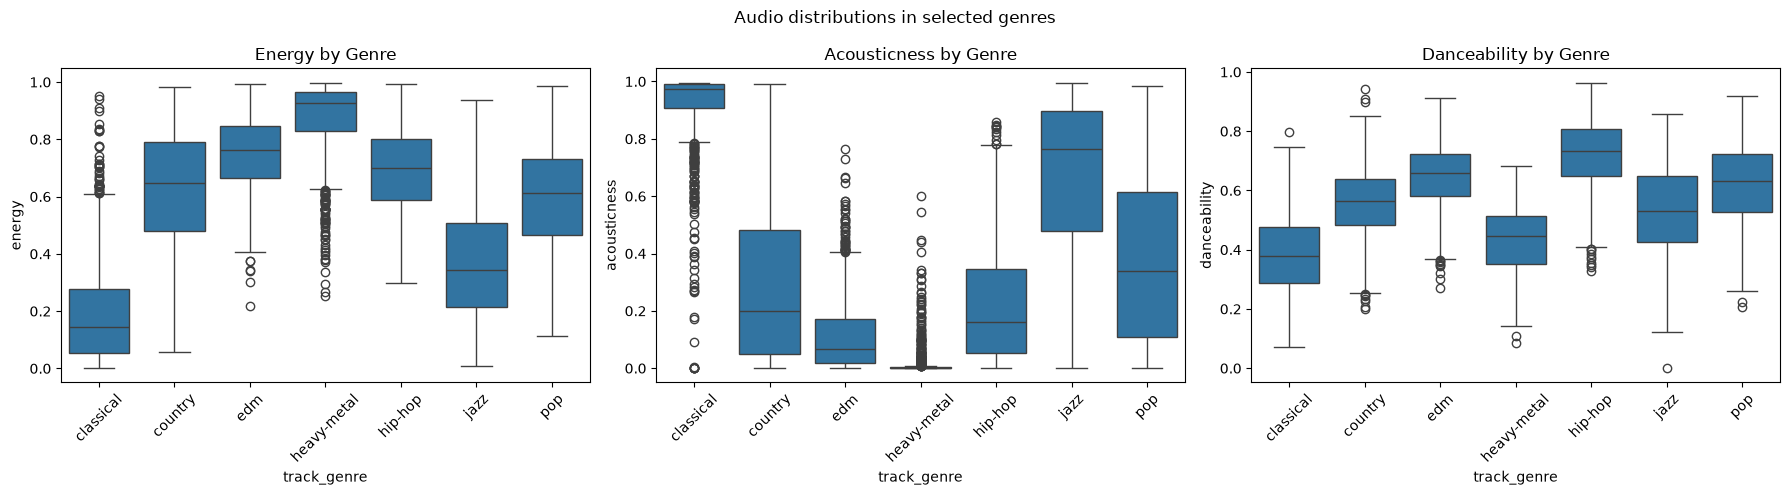

In [15]:
# Boxplots show how a feature changes from genre to genre and also show outliers.
# Show 12 largest genres for readable plots; every genre remains in training.
plot_data = df[df["track_genre"].isin(df["track_genre"].value_counts().head(12).index)]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=plot_data, x="track_genre", y="energy", ax=axes[0])
axes[0].set_title("Energy by Genre")

sns.boxplot(data=plot_data, x="track_genre", y="acousticness", ax=axes[1])
axes[1].set_title("Acousticness by Genre")

sns.boxplot(data=plot_data, x="track_genre", y="danceability", ax=axes[2])
axes[2].set_title("Danceability by Genre")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Audio distributions in selected genres")
plt.tight_layout()
plt.show()

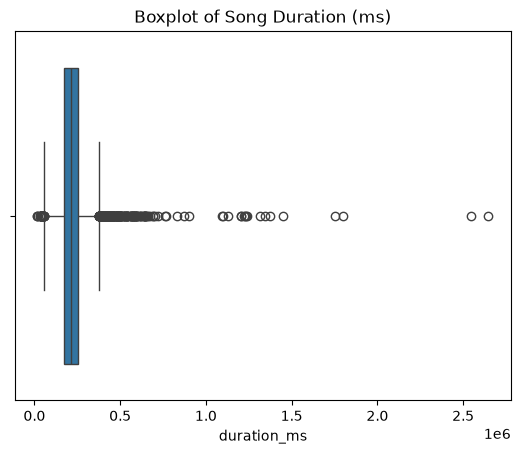

In [16]:
# Boxplot of duration shows outliers (very long songs).
sns.boxplot(x=df["duration_ms"])
plt.title("Boxplot of Song Duration (ms)")
plt.show()

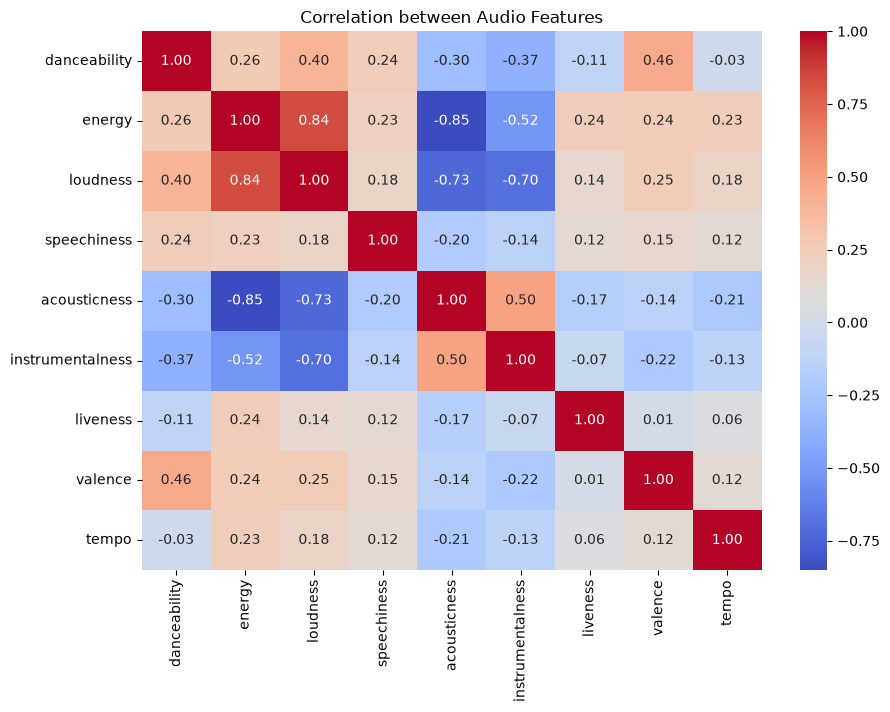

In [17]:
# Correlation heatmap shows which audio features are related to each other.
plt.figure(figsize=(10, 7))
sns.heatmap(df[audio_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between Audio Features")
plt.show()

#### ENCODING

In [18]:
encoder = LabelEncoder()

# "explicit" is True / False, so it is converted into 1 / 0.
df["explicit"] = encoder.fit_transform(df["explicit"])

# Target column: genre names are converted into numbers.
genre_encoder = LabelEncoder()
df["genre_label"] = genre_encoder.fit_transform(df["track_genre"])

print("Genre classes:", list(genre_encoder.classes_))
df[["track_name", "explicit", "track_genre", "genre_label"]].head()

Genre classes: ['classical', 'country', 'edm', 'heavy-metal', 'hip-hop', 'jazz', 'pop']


,track_name,explicit,track_genre,genre_label
0,Zara Zara,0,classical,0
1,Kajra Re,0,classical,0
2,Zara Zara - Lofi,0,classical,0
3,Vaseegara,0,classical,0
4,Zara Zara - LoFi Chill,0,classical,0


#### DEPENDENT AND INDEPENDENT FEATURES

In [19]:
# Audio features are used for genre prediction. Recommendations also add one-hot genre after scaling.
# track_id, artists, album_name, track_name are text and are only used to display recommendations.
# popularity is not used because it describes how famous a song is, not how it sounds.
# key and time_signature are not used because they gave lower accuracy during testing.
feature_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                "instrumentalness", "liveness", "valence", "tempo",
                "duration_ms", "mode", "explicit"]

X = df[feature_cols]
y = df["genre_label"]

print("Number of input features:", X.shape[1])

Number of input features: 12


#### TRAIN TEST SPLIT

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Printing number of samples and features in our TRAINING and TESTING dataset.
print("Number of samples in training dataset: ", X_train.shape[0])
print("Number of features in training dataset: ", X_train.shape[1])
print("Number of samples in testing dataset: ", X_test.shape[0])
print("Number of features in testing dataset: ", X_test.shape[1])

Number of samples in training dataset:  3940
Number of features in training dataset:  12
Number of samples in testing dataset:  985
Number of features in testing dataset:  12


#### FEATURE SCALING

In [21]:
# KNN uses distance, so a feature with large values (duration_ms, tempo) would dominate.
# MinMaxScaler brings every feature into the range 0 to 1.
# The scaler is fitted only on training data so that test data stays unseen.
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=feature_cols).head()

# Recommendation inputs include genre. Classification above/below keeps audio only.
# Known genre categories form a schema; the encoder is fitted on training rows only.
genre_feature_encoder = OneHotEncoder(categories=[genre_encoder.classes_],
                                      sparse_output=False, handle_unknown="error")
train_genres = df.loc[X_train.index, ["track_genre"]]
test_genres = df.loc[X_test.index, ["track_genre"]]
genre_feature_encoder.fit(train_genres)
X_train_recommend = np.hstack([X_train_scaled, genre_feature_encoder.transform(train_genres)])
X_test_recommend = np.hstack([X_test_scaled, genre_feature_encoder.transform(test_genres)])
recommendation_feature_cols = feature_cols + [f"Genre: {genre}" for genre in genre_encoder.classes_]
print("Recommendation inputs:", len(recommendation_feature_cols), "(audio plus one-hot genre)")
print("Genre-classifier inputs:", len(feature_cols), "(audio only, to avoid target leakage)")


Recommendation inputs: 19 (audio plus one-hot genre)
Genre-classifier inputs: 12 (audio only, to avoid target leakage)


## 4. MODEL DEVELOPMENT

#### KNN CLASSIFIER (DEFAULT PARAMETERS)

In [22]:
# Default KNN: K = 5 neighbors, Euclidean distance, all neighbors have equal vote.
knn = KNeighborsClassifier(metric="euclidean")
knn.fit(X_train_scaled, y_train)
print("KNN training completed")
print("Parameters:", knn.get_params())

KNN training completed
Parameters: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}


**KNN with PCA (PR10):** PCA combines features into fewer components, retaining at least
95% of training variance. Fit it on training data only, then transform test data.
Use the same KNN settings for a fair comparison; genre stays out of classifier inputs.

In [23]:
classification_pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = classification_pca.fit_transform(X_train_scaled)
X_test_pca = classification_pca.transform(X_test_scaled)
pca_knn = KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="euclidean")
pca_knn.fit(X_train_pca, y_train)
print(f"Classification features: {X_train_scaled.shape[1]} → {X_train_pca.shape[1]}")
print(f"Retained variance: {classification_pca.explained_variance_ratio_.sum():.2%}")
assert X_train_pca.shape[1] == X_test_pca.shape[1]

Classification features: 12 → 7
Retained variance: 95.01%


#### KNN RECOMMENDER (NEAREST NEIGHBORS)

In [24]:
# The recommender uses the same KNN idea without a target column:
# it simply finds the K songs whose audio and genre features are closest to the given song.
all_songs_scaled = np.hstack([scaler.transform(X),
                               genre_feature_encoder.transform(df[["track_genre"]])])

recommender = NearestNeighbors(n_neighbors=11, metric="euclidean")
recommender.fit(all_songs_scaled)

print("Recommender is ready. Songs in catalogue:", all_songs_scaled.shape[0])

Recommender is ready. Songs in catalogue: 4925


In [25]:
def recommend_songs(song_name, model, n_recommendations=10, catalogue_features=None):
    """Rank nearby songs, restricting candidates to the cluster for clustering models."""
    catalogue_features = all_songs_scaled if catalogue_features is None else catalogue_features
    matches = df[df["track_name"].str.lower() == song_name.lower()]
    if matches.empty:
        print(f"'{song_name}' is not present in the dataset.")
        return None
    song_index = matches.index[0]
    song = df.loc[song_index]
    print(f"Input Song: {song['track_name']} | Artist: {song['artists']} | Genre: {song['track_genre']}")
    if isinstance(model, ClusterRecommender):
        distances, indices = model.recommend(
            catalogue_features, catalogue_features[[song_index]], n_recommendations, best_metric,
            cluster=model.labels[song_index], exclude=song_index)
    else:
        distances, indices = model.kneighbors(catalogue_features[[song_index]],
                                              n_neighbors=min(n_recommendations + 1, len(df)))
        keep = indices[0] != song_index
        indices, distances = indices[0][keep][:n_recommendations], distances[0][keep][:n_recommendations]
    result = df.loc[indices, ["track_name", "artists", "track_genre"]].copy()
    result["distance"] = distances.round(4)
    if len(result) < n_recommendations:
        print(f"Only {len(result)} other songs are available in this cluster.")
    return result.reset_index(drop=True)

In [26]:
recommend_songs("Nuvole Bianche", recommender)

Input Song: Nuvole Bianche | Artist: Ludovico Einaudi | Genre: classical


,track_name,artists,track_genre,distance
0,"Piano Concerto No. 27 in B-Flat Major, K. 595:...",Wolfgang Amadeus Mozart;Wilhelm Kempff;Berline...,classical,0.1136
1,"Nabucco: Va, pensiero, sull'ali dorate - Edit",Giuseppe Verdi;Chicago Symphony Chorus;Chicago...,classical,0.1417
2,"Adagio in F, K.410",Wolfgang Amadeus Mozart;Holliger Wind Ensemble,classical,0.1635
3,"Saul, HWV 53: Dead March",George Frideric Handel;London Early Opera;Brid...,classical,0.1670
4,Una Mattina,Ludovico Einaudi,classical,0.1735
5,"Cello Sonata in C Major, Op. 119: I. Andante g...",Sergei Prokofiev;Miriam K. Smith;Sandra Wright...,classical,0.1834
6,"Piano Concerto No. 23 in A Major, K. 488: II. ...",Wolfgang Amadeus Mozart;Ingrid Haebler;London ...,classical,0.1962
7,Box of Memories,Josh Kramer,classical,0.1996
8,Orfeo Ed Euridice: Dance of the Blessed Spirit...,Christoph Willibald Gluck;Karlheinz Zoeller;Be...,classical,0.2121
9,"Ma mère l'Oye, M. 60: Apothéose: Le jardin fée...",Maurice Ravel;Michael Davis;London Symphony Or...,classical,0.2140


**PCA recommendations:** fit a separate PCA on training audio + one-hot genre.
Transform the catalogue with it, then retrieve songs using Euclidean distance.

In [27]:
recommendation_pca = PCA(n_components=0.95, svd_solver="full")
X_train_recommend_pca = recommendation_pca.fit_transform(X_train_recommend)
X_test_recommend_pca = recommendation_pca.transform(X_test_recommend)
all_songs_pca = recommendation_pca.transform(all_songs_scaled)
pca_recommender = NearestNeighbors(metric="euclidean").fit(all_songs_pca)
print(f"Recommendation features: {X_train_recommend.shape[1]} → {all_songs_pca.shape[1]}")
print(f"Retained variance: {recommendation_pca.explained_variance_ratio_.sum():.2%}")
display(recommend_songs("Nuvole Bianche", pca_recommender, catalogue_features=all_songs_pca))
assert np.isfinite(all_songs_pca).all()

Recommendation features: 19 → 11
Retained variance: 95.29%
Input Song: Nuvole Bianche | Artist: Ludovico Einaudi | Genre: classical


,track_name,artists,track_genre,distance
0,"Nocturne No. 6 in D flat, Op. 63",Gabriel Fauré;Kun-Woo Paik,classical,0.0431
1,"Cello Sonata in C Major, Op. 119: I. Andante g...",Sergei Prokofiev;Miriam K. Smith;Sandra Wright...,classical,0.0444
2,"24 Preludes, Op. 28: No. 1 in C Major. Agitato",Frédéric Chopin;Alice Sara Ott,classical,0.0451
3,"Peer Gynt Suite No. 1, Op. 46: I. Morning Mood",Edvard Grieg;Berliner Philharmoniker;Herbert v...,classical,0.0487
4,Ave Maria,Johann Sebastian Bach;Charles Gounod;Kian Solt...,classical,0.0504
5,"Ave verum corpus, K. 618 (Arr. Spindler for En...",Wolfgang Amadeus Mozart;Albrecht Mayer;Vital J...,classical,0.0505
6,"Liebeslied (Widmung), S. 566",Franz Liszt;YUNDI,classical,0.0541
7,"Fantaisie-Impromptu In C-Sharp Minor, Op. 66",Frédéric Chopin;Daniil Trifonov,classical,0.0583
8,"Piano Concerto No. 15 in B-Flat Major, K. 450:...",Wolfgang Amadeus Mozart;Ingrid Haebler;London ...,classical,0.0584
9,"Piano Concerto No. 27 in B-Flat Major, K. 595:...",Wolfgang Amadeus Mozart;Wilhelm Kempff;Berline...,classical,0.0616


## 5. PERFORMANCE EVALUATION

#### GENRE PREDICTION METRICS

In [28]:
# Predict on testing data
y_pred = knn.predict(X_test_scaled)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.5756
Precision: 0.5723
Recall   : 0.5756
F1-Score : 0.5684


In [29]:
print(classification_report(y_test, y_pred, target_names=genre_encoder.classes_))

              precision    recall  f1-score   support

   classical       0.87      0.80      0.83       163
     country       0.39      0.50      0.44       121
         edm       0.41      0.50      0.45       135
 heavy-metal       0.80      0.87      0.83       197
     hip-hop       0.52      0.52      0.52       145
        jazz       0.42      0.37      0.39        95
         pop       0.36      0.19      0.25       129

    accuracy                           0.58       985
   macro avg       0.54      0.54      0.53       985
weighted avg       0.57      0.58      0.57       985



#### CONFUSION MATRIX

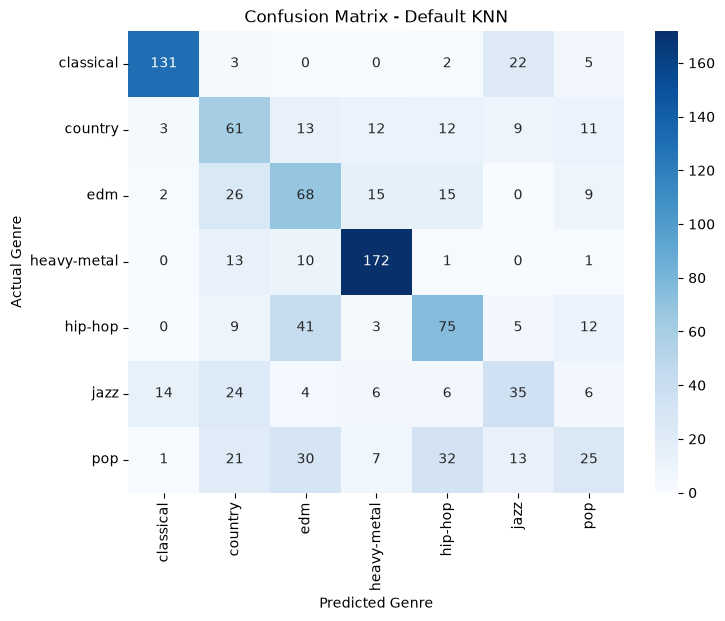

In [30]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=len(genre_encoder.classes_) <= 15, fmt="d", cmap="Blues",
            xticklabels=genre_encoder.classes_ if len(genre_encoder.classes_) <= 15 else False,
            yticklabels=genre_encoder.classes_ if len(genre_encoder.classes_) <= 15 else False)
plt.title("Confusion Matrix - Default KNN")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.show()

**Effect of PCA on KNN:** compare default classifiers on the same test songs.
The plot shows only the first two components; KNN uses all components retained for 95%
variance. Retained variance does not guarantee better accuracy.

,Model,Features,Accuracy,Precision,Recall,F1
0,KNN,12,0.5756,0.5723,0.5756,0.5684
1,KNN + PCA,7,0.5147,0.5077,0.5147,0.5066


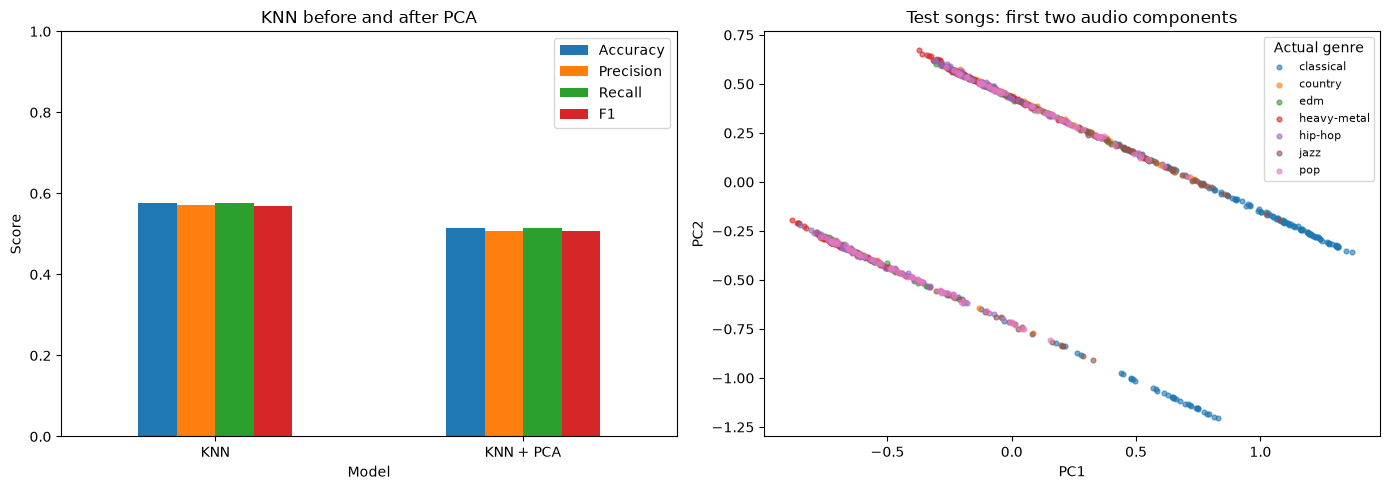

In [31]:
y_pred_pca = pca_knn.predict(X_test_pca)
pca_comparison = pd.DataFrame({
    "Model": ["KNN", "KNN + PCA"],
    "Features": [X_train_scaled.shape[1], X_train_pca.shape[1]],
    "Accuracy": [accuracy, accuracy_score(y_test, y_pred_pca)],
    "Precision": [precision, precision_score(y_test, y_pred_pca, average="weighted", zero_division=0)],
    "Recall": [recall, recall_score(y_test, y_pred_pca, average="weighted", zero_division=0)],
    "F1": [f1, f1_score(y_test, y_pred_pca, average="weighted", zero_division=0)],
})
display(pca_comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pca_comparison.plot.bar(x="Model", y=["Accuracy", "Precision", "Recall", "F1"],
                        ylim=(0, 1), rot=0, ax=axes[0])
axes[0].set(title="KNN before and after PCA", ylabel="Score")
for genre_id, genre in enumerate(genre_encoder.classes_):
    mask = y_test.to_numpy() == genre_id
    axes[1].scatter(X_test_pca[mask, 0], X_test_pca[mask, 1], s=12, alpha=0.6, label=genre)
axes[1].set(title="Test songs: first two audio components", xlabel="PC1", ylabel="PC2")
axes[1].legend(title="Actual genre", fontsize=8)
plt.tight_layout()
plt.show()

#### RECOMMENDATION QUALITY: PRECISION@10

For each test song, retrieve training songs using scaled audio features plus known genre.
Precision@10 checks same-genre matches. Because genre is an input, this is a
**genre-consistency diagnostic**, not independent evidence of recommendation quality.
Genre-classification metrics remain separate and use audio inputs only.

In [32]:
def precision_at_k(model, k=10):
    """Average fraction of the k recommended songs that share the input song's genre."""

    model.fit(X_train_recommend)
    distances, indices = model.kneighbors(X_test_recommend, n_neighbors=k)

    train_genres = y_train.values
    test_genres = y_test.values

    # For each test song: count neighbours with the same genre, divide by k.
    hits = (train_genres[indices] == test_genres[:, None]).sum(axis=1)
    return (hits / k).mean()


default_p_at_10 = precision_at_k(NearestNeighbors(metric="euclidean"), k=10)
print("Precision@10 (default recommender):", round(default_p_at_10, 4))

Precision@10 (default recommender): 1.0


In [33]:
# PCA recommendation evaluation uses training candidates and held-out test queries.
pca_eval_recommender = NearestNeighbors(metric="euclidean").fit(X_train_recommend_pca)
_, pca_indices = pca_eval_recommender.kneighbors(X_test_recommend_pca, n_neighbors=10)
pca_p_at_10 = (y_train.to_numpy()[pca_indices] == y_test.to_numpy()[:, None]).mean()
print(f"Precision@10 — KNN: {default_p_at_10:.4f}; KNN + PCA: {pca_p_at_10:.4f}")
print("Genre is an input: this measures genre consistency, not listener satisfaction.")
assert 0 <= pca_p_at_10 <= 1

Precision@10 — KNN: 1.0000; KNN + PCA: 1.0000
Genre is an input: this measures genre consistency, not listener satisfaction.


#### CHOOSING THE VALUE OF K

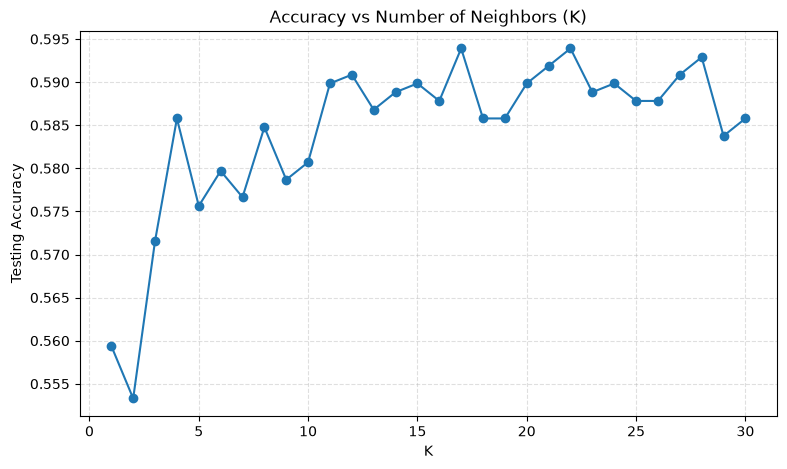

Best K from this graph: 17 with accuracy 0.5939


In [34]:
# Train KNN for different values of K and record the testing accuracy.
k_values = range(1, 31)
k_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    model.fit(X_train_scaled, y_train)
    k_accuracy.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.figure(figsize=(9, 5))
plt.plot(k_values, k_accuracy, marker="o")
plt.title("Accuracy vs Number of Neighbors (K)")
plt.xlabel("K")
plt.ylabel("Testing Accuracy")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

print("Best K from this graph:", k_values[int(np.argmax(k_accuracy))], "with accuracy", round(max(k_accuracy), 4))

## 6. MODEL OPTIMIZATION

#### CROSS VALIDATION (DEFAULT KNN)

In [35]:
scores = cross_val_score(KNeighborsClassifier(metric="euclidean"), X_train_scaled, y_train, cv=5, scoring="accuracy")

print("Fold accuracies:", scores.round(4))
print("Mean CV Accuracy:", round(scores.mean() * 100, 2), "%")
print("CV Standard Deviation:", round(scores.std(), 4))

Fold accuracies: [0.566  0.5711 0.5622 0.5635 0.5698]
Mean CV Accuracy: 56.65 %
CV Standard Deviation: 0.0035


#### HYPERPARAMETER TUNING

In [36]:
# 1. Define parameter grid
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25, 31],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean"]
}

# 2. Perform Grid Search CV
grid = GridSearchCV(
    KNeighborsClassifier(metric="euclidean"),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

best_knn = grid.best_estimator_

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", round(grid.best_score_ * 100, 2), "%")

Best Parameters: {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'distance'}
Best CV Accuracy: 60.28 %


In [37]:
# Top 5 parameter combinations tried by Grid Search
grid_results = pd.DataFrame(grid.cv_results_)
grid_results = grid_results[["param_n_neighbors", "param_weights", "param_metric", "mean_test_score"]]
grid_results.sort_values("mean_test_score", ascending=False).head(5)

,param_n_neighbors,param_weights,param_metric,mean_test_score
11,15,distance,euclidean,0.602792
17,31,distance,euclidean,0.602792
9,11,distance,euclidean,0.601777
15,25,distance,euclidean,0.600761
13,21,distance,euclidean,0.600254


#### EVALUATING OPTIMIZED KNN

In [38]:
# 3. Evaluate optimized model
y_pred_tuned = best_knn.predict(X_test_scaled)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned, average="weighted", zero_division=0)
tuned_recall = recall_score(y_test, y_pred_tuned, average="weighted", zero_division=0)
tuned_f1 = f1_score(y_test, y_pred_tuned, average="weighted", zero_division=0)

print("Testing Accuracy:", round(tuned_accuracy * 100, 2), "%")
print("Precision:", round(tuned_precision, 4))
print("Recall:", round(tuned_recall, 4))
print("F1-Score:", round(tuned_f1, 4))

Testing Accuracy: 61.22 %
Precision: 0.6053
Recall: 0.6122
F1-Score: 0.6048


In [39]:
print(classification_report(y_test, y_pred_tuned, target_names=genre_encoder.classes_))

              precision    recall  f1-score   support

   classical       0.91      0.79      0.85       163
     country       0.49      0.54      0.51       121
         edm       0.45      0.50      0.47       135
 heavy-metal       0.76      0.92      0.83       197
     hip-hop       0.59      0.59      0.59       145
        jazz       0.47      0.42      0.44        95
         pop       0.37      0.26      0.31       129

    accuracy                           0.61       985
   macro avg       0.58      0.58      0.57       985
weighted avg       0.61      0.61      0.60       985



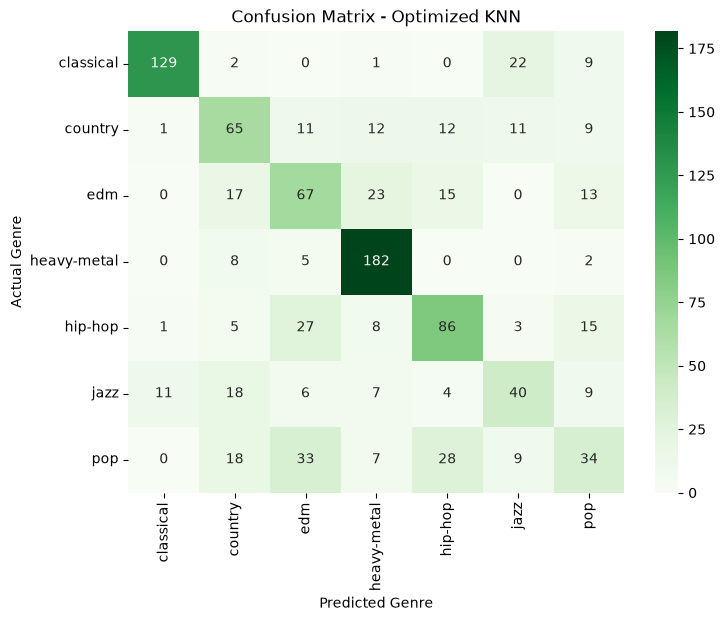

In [40]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_tuned, annot=len(genre_encoder.classes_) <= 15, fmt="d", cmap="Greens",
            xticklabels=genre_encoder.classes_ if len(genre_encoder.classes_) <= 15 else False,
            yticklabels=genre_encoder.classes_ if len(genre_encoder.classes_) <= 15 else False)
plt.title("Confusion Matrix - Optimized KNN")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.show()

#### OPTIMIZED RECOMMENDER

In [41]:
# Euclidean distance is fixed everywhere; tuning K and weights changes genre voting only.
best_metric = "euclidean"

tuned_p_at_10 = precision_at_k(NearestNeighbors(metric=best_metric), k=10)
print("Precision@10 (optimized recommender, metric =", best_metric + "):", round(tuned_p_at_10, 4))

# Fit the final recommender on all songs so that any song can be searched.
best_recommender = NearestNeighbors(n_neighbors=11, metric=best_metric)
best_recommender.fit(all_songs_scaled)
print("Optimized recommender is ready.")

Precision@10 (optimized recommender, metric = euclidean): 1.0
Optimized recommender is ready.


## 7. RESULT ANALYSIS AND DOCUMENTATION

#### BEFORE vs AFTER OPTIMIZATION

In [42]:
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "CV Accuracy", "Precision@10"],
    "Default KNN": [accuracy, precision, recall, f1, scores.mean(), default_p_at_10],
    "Optimized KNN": [tuned_accuracy, tuned_precision, tuned_recall, tuned_f1, grid.best_score_, tuned_p_at_10]
})

comparison_df["Improvement"] = comparison_df["Optimized KNN"] - comparison_df["Default KNN"]
print(comparison_df.round(4))

         Metric  Default KNN  Optimized KNN  Improvement
0      Accuracy       0.5756         0.6122       0.0365
1     Precision       0.5723         0.6053       0.0330
2        Recall       0.5756         0.6122       0.0365
3      F1-Score       0.5684         0.6048       0.0364
4   CV Accuracy       0.5665         0.6028       0.0363
5  Precision@10       1.0000         1.0000       0.0000


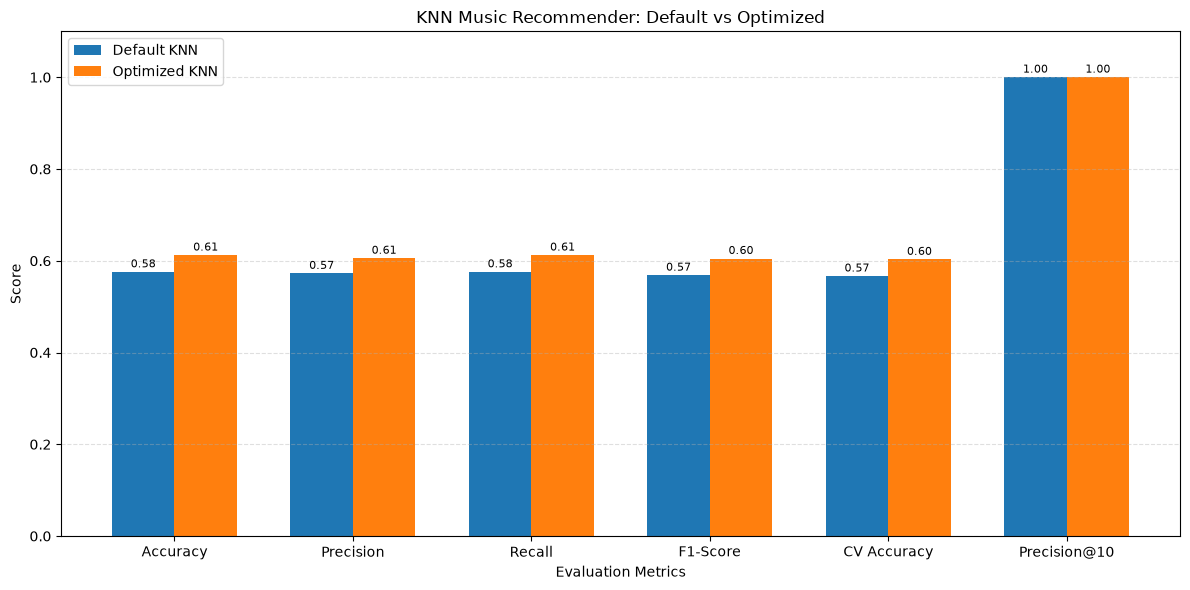

In [43]:
# Plot all metrics in one graph
metrics = comparison_df["Metric"]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(x - width / 2, comparison_df["Default KNN"], width, label="Default KNN")
bars2 = plt.bar(x + width / 2, comparison_df["Optimized KNN"], width, label="Optimized KNN")

for bar in list(bars1) + list(bars2):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{bar.get_height():.2f}",
        ha="center",
        fontsize=8
    )

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("KNN Music Recommender: Default vs Optimized")
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

#### COMPARISON: KNN, K-MEANS AND HIERARCHICAL RECOMMENDATIONS

Following PR7 and PR9, recommend songs with all three methods using the same scaled features,
training candidates and unseen test queries. The shared helper fits sklearn `KMeans` and
`AgglomerativeClustering(linkage="ward")`. Both clustering models receive scaled audio features and one-hot genre inputs. Genre numbers are not treated as ordered distances.

- **KNN:** rank all training candidates by Euclidean distance.
- **K-Means:** assign a test song to its nearest centroid, then rank candidates in that cluster.
- **Hierarchical:** build Ward clusters; assign unseen songs to the nearest training-cluster centroid,
  then rank candidates in that cluster. Nearest-centroid assignment is an explicit extension because
  agglomerative clustering has no native `predict` operation.
- **Precision@10:** same-genre recommendations divided by 10, averaged over test songs.
- **Coverage@10:** returned recommendations divided by 10. Missing slots count as misses in Precision@10;
  there is no backfilling from other clusters.
- **Runtime:** fitting seconds and query milliseconds per song; fitting excludes elbow diagnostics.

For a manageable hierarchical fit, all three comparison methods use the same reproducible sample of
at most **5,000 training songs and 1,000 test songs**, stratified where possible. The previous seven genres are selected by default; every cleaned song from those genres stays in the interactive catalogue.
The comparison uses the same capped training/test samples for all three methods. The scaler is fitted on training data only.
Cluster count is set below. Use `None` for automatic detection from the training-only elbow curve, or an integer to override it. The same count is used for both clustering models.
Euclidean distance is fixed for every method. Grid search tunes only K and voting weights; it does not change the recommendation distance.
Genre is an input, so Precision@10 measures genre consistency and is expected to be high. It is not an independent measure of recommendation quality or listener satisfaction.

Same 3940 training and 985 test songs for every method.
       Model  Precision@10  Coverage@10  Fit seconds  Query ms/song
         KNN        1.0000       1.0000       0.0009         0.0220
     K-Means        1.0000       1.0000       0.0538         0.8789
Hierarchical        1.0000       1.0000       0.7288         0.9407
Cluster count: 7 Selection: manual


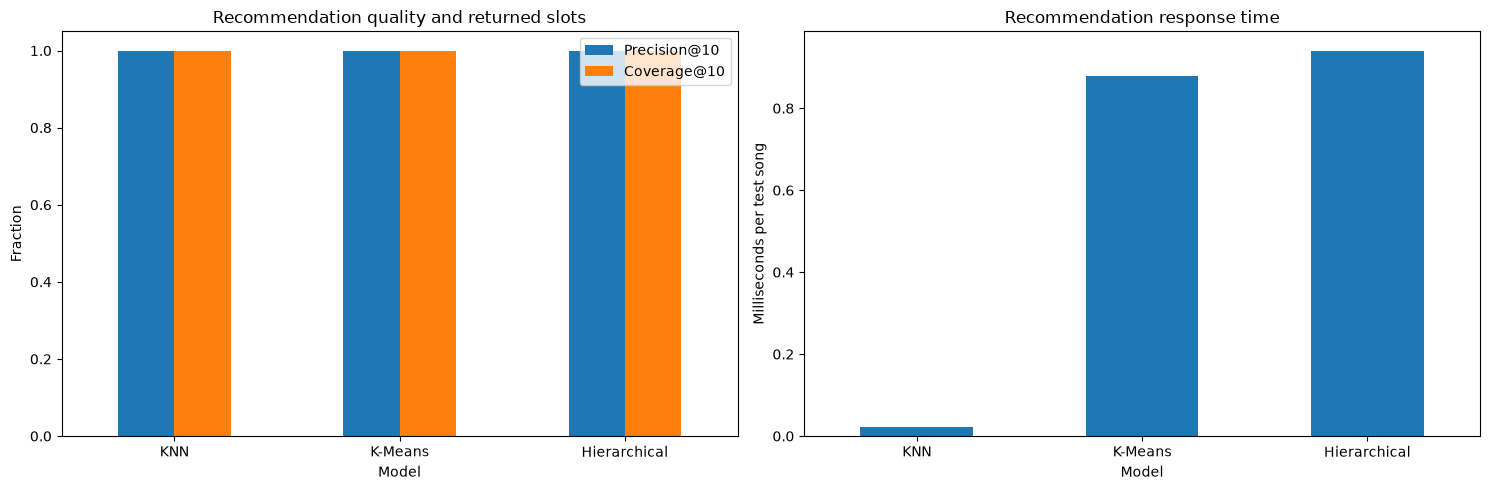

In [44]:
# Set None to detect the elbow automatically; an integer overrides detection.
n_clusters = 7
cluster_models, recommendation_comparison, clustering_diagnostics = compare_recommenders(
    X_train_recommend, y_train.to_numpy(), X_test_recommend, y_test.to_numpy(),
    metric=best_metric, k=10, n_clusters=n_clusters, random_state=42)

recommendation_table = recommendation_comparison["table"].sort_values(
    "Precision@10", ascending=False, kind="stable").reset_index(drop=True)
assert set(recommendation_table["Model"]) == {"KNN", "K-Means", "Hierarchical"}
assert recommendation_table["Precision@10"].between(0, 1).all()
print(f"Same {recommendation_comparison['train_songs']} training and "
      f"{recommendation_comparison['test_songs']} test songs for every method.")
print(recommendation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print("Cluster count:", recommendation_comparison["n_clusters"],
      "Selection:", recommendation_comparison["cluster_selection"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
recommendation_table.plot.bar(x="Model", y=["Precision@10", "Coverage@10"],
                              ylim=(0, 1.05), rot=0, ax=axes[0])
axes[0].set(title="Recommendation quality and returned slots", ylabel="Fraction")
recommendation_table.plot.bar(x="Model", y="Query ms/song", rot=0, legend=False, ax=axes[1])
axes[1].set(title="Recommendation response time", ylabel="Milliseconds per test song")
plt.tight_layout()
plt.show()

# For interactive use, assign other catalogue songs to learned centroids.
# Preserve the original memberships of songs actually used for clustering.
fitted_indices = X_train.index.to_numpy()[recommendation_comparison["train_indices"]]
catalogue_clusters = {}
for name, model in cluster_models.items():
    labels = model.predict(all_songs_scaled)
    labels[fitted_indices] = model.labels
    catalogue_clusters[name] = replace(model, labels=labels)
recommendation_models = {"KNN": best_recommender, **catalogue_clusters}

#### CLUSTER ANALYSIS: ELBOW PLOT AND DENDROGRAM (PR9)

The elbow plot shows K-Means training inertia. Look for a bend; the red line shows the chosen count. The dendrogram shows the last 25 hierarchical groups and the distance at which they merge. These plots guide cluster count selection without using test results.

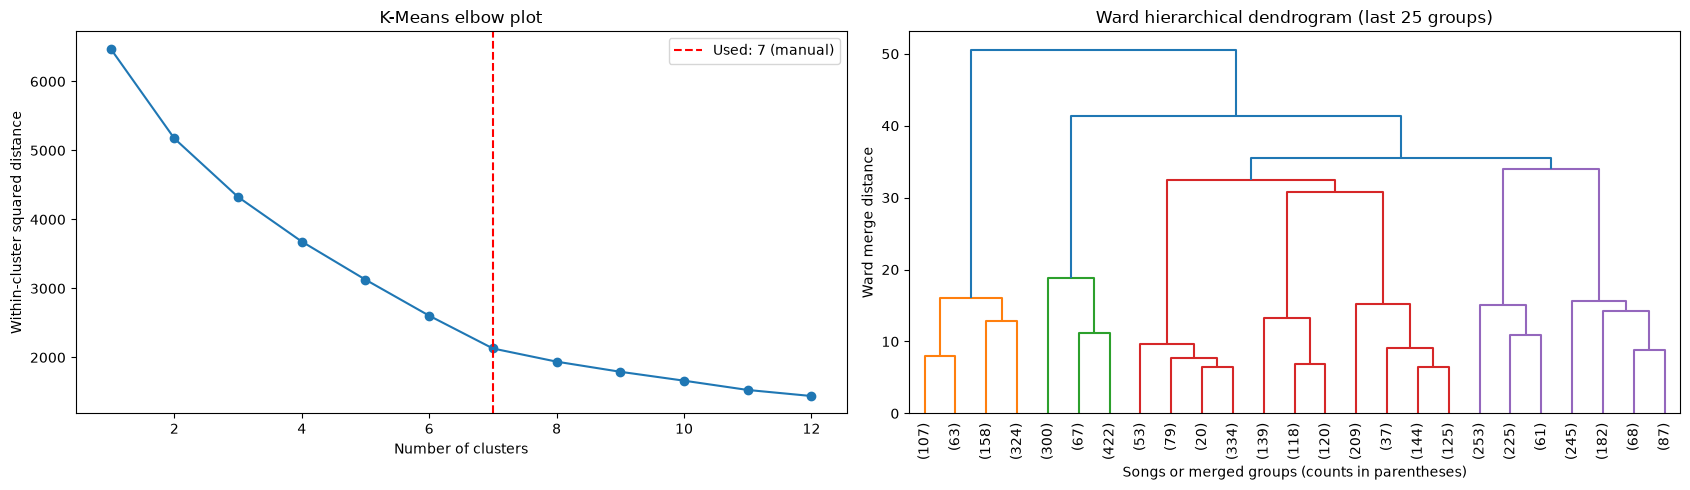

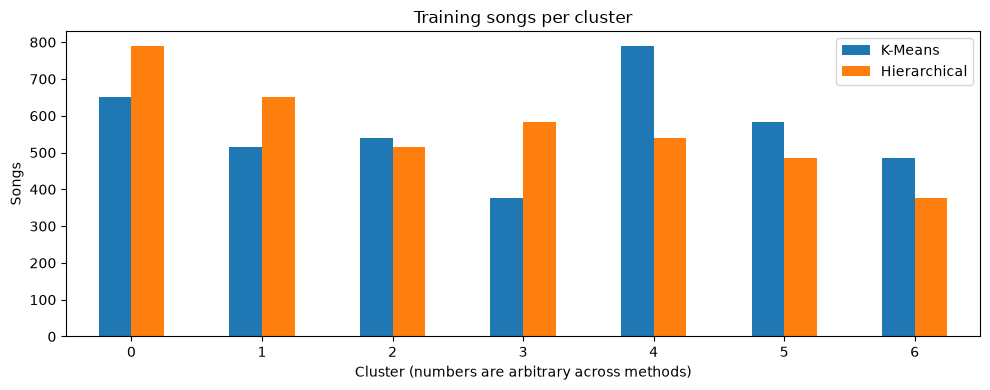

In [45]:
elbow = clustering_diagnostics["elbow"]
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].plot(elbow["Clusters"], elbow["Inertia"], marker="o")
used_clusters = recommendation_comparison["n_clusters"]
axes[0].axvline(used_clusters, color="red", linestyle="--",
                label=f"Used: {used_clusters} ({recommendation_comparison['cluster_selection']})")
axes[0].set(title="K-Means elbow plot", xlabel="Number of clusters", ylabel="Within-cluster squared distance")
axes[0].legend()
dendrogram(clustering_diagnostics["linkage"], truncate_mode="lastp", p=25,
           show_leaf_counts=True, ax=axes[1])
axes[1].set(title="Ward hierarchical dendrogram (last 25 groups)",
            xlabel="Songs or merged groups (counts in parentheses)", ylabel="Ward merge distance")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

clustering_diagnostics["cluster_sizes"].plot.bar(figsize=(10, 4), rot=0)
plt.title("Training songs per cluster")
plt.xlabel("Cluster (numbers are arbitrary across methods)")
plt.ylabel("Songs")
plt.tight_layout()
plt.show()

#### GENRE-WISE PERFORMANCE

      Genre  F1-Score
  classical    0.8459
heavy-metal    0.8330
    hip-hop    0.5931
    country    0.5118
        edm    0.4718
       jazz    0.4444
        pop    0.3091


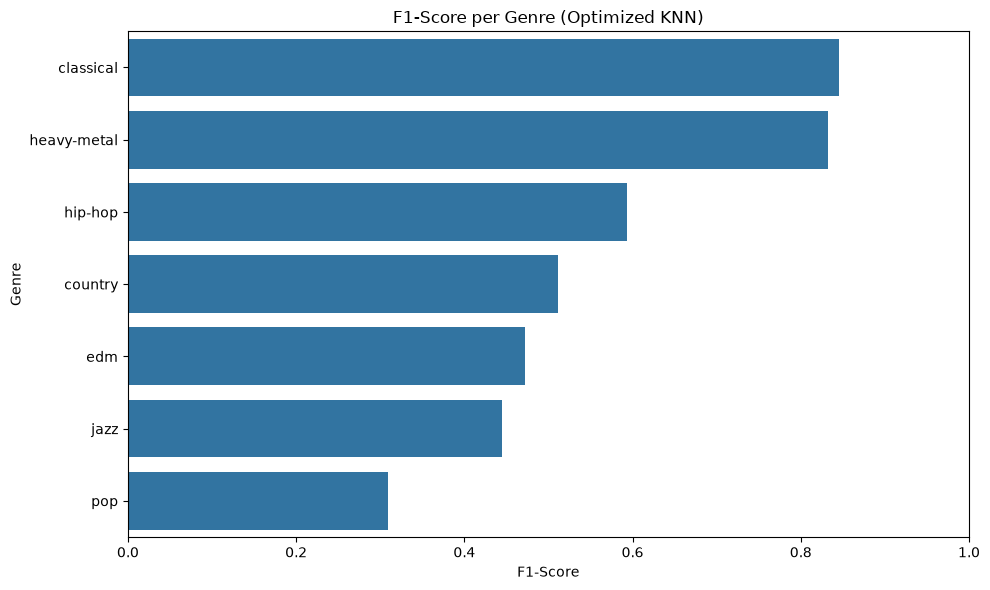

In [46]:
# F1-Score of each genre for the optimized model.
genre_f1 = f1_score(y_test, y_pred_tuned, average=None)

genre_df = pd.DataFrame({"Genre": genre_encoder.classes_, "F1-Score": genre_f1})
genre_df = genre_df.sort_values("F1-Score", ascending=False)
print(genre_df.round(4).to_string(index=False))

plt.figure(figsize=(10, max(6, len(genre_df) * 0.19)))
sns.barplot(data=genre_df, x="F1-Score", y="Genre")
plt.title("F1-Score per Genre (Optimized KNN)")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

#### SAMPLE RECOMMENDATIONS FROM ALL THREE METHODS

In [47]:
for name, model in recommendation_models.items():
    print("\nRecommendation method:", name)
    display(recommend_songs('Nuvole Bianche', model))


Recommendation method: KNN
Input Song: Nuvole Bianche | Artist: Ludovico Einaudi | Genre: classical


,track_name,artists,track_genre,distance
0,"Piano Concerto No. 27 in B-Flat Major, K. 595:...",Wolfgang Amadeus Mozart;Wilhelm Kempff;Berline...,classical,0.1136
1,"Nabucco: Va, pensiero, sull'ali dorate - Edit",Giuseppe Verdi;Chicago Symphony Chorus;Chicago...,classical,0.1417
2,"Adagio in F, K.410",Wolfgang Amadeus Mozart;Holliger Wind Ensemble,classical,0.1635
3,"Saul, HWV 53: Dead March",George Frideric Handel;London Early Opera;Brid...,classical,0.1670
4,Una Mattina,Ludovico Einaudi,classical,0.1735
5,"Cello Sonata in C Major, Op. 119: I. Andante g...",Sergei Prokofiev;Miriam K. Smith;Sandra Wright...,classical,0.1834
6,"Piano Concerto No. 23 in A Major, K. 488: II. ...",Wolfgang Amadeus Mozart;Ingrid Haebler;London ...,classical,0.1962
7,Box of Memories,Josh Kramer,classical,0.1996
8,Orfeo Ed Euridice: Dance of the Blessed Spirit...,Christoph Willibald Gluck;Karlheinz Zoeller;Be...,classical,0.2121
9,"Ma mère l'Oye, M. 60: Apothéose: Le jardin fée...",Maurice Ravel;Michael Davis;London Symphony Or...,classical,0.2140



Recommendation method: K-Means
Input Song: Nuvole Bianche | Artist: Ludovico Einaudi | Genre: classical


,track_name,artists,track_genre,distance
0,"Piano Concerto No. 27 in B-Flat Major, K. 595:...",Wolfgang Amadeus Mozart;Wilhelm Kempff;Berline...,classical,0.1136
1,"Nabucco: Va, pensiero, sull'ali dorate - Edit",Giuseppe Verdi;Chicago Symphony Chorus;Chicago...,classical,0.1417
2,"Adagio in F, K.410",Wolfgang Amadeus Mozart;Holliger Wind Ensemble,classical,0.1635
3,"Saul, HWV 53: Dead March",George Frideric Handel;London Early Opera;Brid...,classical,0.1670
4,Una Mattina,Ludovico Einaudi,classical,0.1735
5,"Cello Sonata in C Major, Op. 119: I. Andante g...",Sergei Prokofiev;Miriam K. Smith;Sandra Wright...,classical,0.1834
6,"Piano Concerto No. 23 in A Major, K. 488: II. ...",Wolfgang Amadeus Mozart;Ingrid Haebler;London ...,classical,0.1962
7,Box of Memories,Josh Kramer,classical,0.1996
8,Orfeo Ed Euridice: Dance of the Blessed Spirit...,Christoph Willibald Gluck;Karlheinz Zoeller;Be...,classical,0.2121
9,"Ma mère l'Oye, M. 60: Apothéose: Le jardin fée...",Maurice Ravel;Michael Davis;London Symphony Or...,classical,0.2140



Recommendation method: Hierarchical
Input Song: Nuvole Bianche | Artist: Ludovico Einaudi | Genre: classical


,track_name,artists,track_genre,distance
0,"Piano Concerto No. 27 in B-Flat Major, K. 595:...",Wolfgang Amadeus Mozart;Wilhelm Kempff;Berline...,classical,0.1136
1,"Nabucco: Va, pensiero, sull'ali dorate - Edit",Giuseppe Verdi;Chicago Symphony Chorus;Chicago...,classical,0.1417
2,"Adagio in F, K.410",Wolfgang Amadeus Mozart;Holliger Wind Ensemble,classical,0.1635
3,"Saul, HWV 53: Dead March",George Frideric Handel;London Early Opera;Brid...,classical,0.1670
4,Una Mattina,Ludovico Einaudi,classical,0.1735
5,"Cello Sonata in C Major, Op. 119: I. Andante g...",Sergei Prokofiev;Miriam K. Smith;Sandra Wright...,classical,0.1834
6,"Piano Concerto No. 23 in A Major, K. 488: II. ...",Wolfgang Amadeus Mozart;Ingrid Haebler;London ...,classical,0.1962
7,Box of Memories,Josh Kramer,classical,0.1996
8,Orfeo Ed Euridice: Dance of the Blessed Spirit...,Christoph Willibald Gluck;Karlheinz Zoeller;Be...,classical,0.2121
9,"Ma mère l'Oye, M. 60: Apothéose: Le jardin fée...",Maurice Ravel;Michael Davis;London Symphony Or...,classical,0.2140


In [48]:
for name, model in recommendation_models.items():
    print("\nRecommendation method:", name)
    display(recommend_songs('Super Freaky Girl', model))


Recommendation method: KNN
Input Song: Super Freaky Girl | Artist: Nicki Minaj | Genre: hip-hop


,track_name,artists,track_genre,distance
0,RAP DEVIL,Machine Gun Kelly,hip-hop,0.2668
1,BOP,DaBaby,hip-hop,0.3520
2,Big Daddy Wiz,Wiz Khalifa;Girl Talk,hip-hop,0.3691
3,The Valley of the Pagans,Gorillaz;Beck,hip-hop,0.3710
4,Money Rain - Phonk Remix,VTORNIK;Phonk,hip-hop,0.4089
5,Without Me,Eminem,hip-hop,0.4144
6,SUNDOWN,Jack Harlow,hip-hop,0.4374
7,Pind Da Riwaaz,Wazir Patar;Azaad,hip-hop,0.4380
8,Se Menea,Don Omar;Nio Garcia,hip-hop,0.4425
9,Unforgettable,French Montana;Swae Lee,hip-hop,0.4436



Recommendation method: K-Means
Input Song: Super Freaky Girl | Artist: Nicki Minaj | Genre: hip-hop


,track_name,artists,track_genre,distance
0,RAP DEVIL,Machine Gun Kelly,hip-hop,0.2668
1,BOP,DaBaby,hip-hop,0.3520
2,Big Daddy Wiz,Wiz Khalifa;Girl Talk,hip-hop,0.3691
3,The Valley of the Pagans,Gorillaz;Beck,hip-hop,0.3710
4,Money Rain - Phonk Remix,VTORNIK;Phonk,hip-hop,0.4089
5,Without Me,Eminem,hip-hop,0.4144
6,SUNDOWN,Jack Harlow,hip-hop,0.4374
7,Pind Da Riwaaz,Wazir Patar;Azaad,hip-hop,0.4380
8,Se Menea,Don Omar;Nio Garcia,hip-hop,0.4425
9,Unforgettable,French Montana;Swae Lee,hip-hop,0.4436



Recommendation method: Hierarchical
Input Song: Super Freaky Girl | Artist: Nicki Minaj | Genre: hip-hop


,track_name,artists,track_genre,distance
0,RAP DEVIL,Machine Gun Kelly,hip-hop,0.2668
1,BOP,DaBaby,hip-hop,0.3520
2,Big Daddy Wiz,Wiz Khalifa;Girl Talk,hip-hop,0.3691
3,The Valley of the Pagans,Gorillaz;Beck,hip-hop,0.3710
4,Money Rain - Phonk Remix,VTORNIK;Phonk,hip-hop,0.4089
5,Without Me,Eminem,hip-hop,0.4144
6,SUNDOWN,Jack Harlow,hip-hop,0.4374
7,Pind Da Riwaaz,Wazir Patar;Azaad,hip-hop,0.4380
8,Se Menea,Don Omar;Nio Garcia,hip-hop,0.4425
9,Unforgettable,French Montana;Swae Lee,hip-hop,0.4436


In [49]:
for name, model in recommendation_models.items():
    print("\nRecommendation method:", name)
    display(recommend_songs('Balls to the Wall', model))


Recommendation method: KNN
Input Song: Balls to the Wall | Artist: Accept | Genre: heavy-metal


,track_name,artists,track_genre,distance
0,Enroscando Al Mundo,OConnor,heavy-metal,0.1225
1,Emmauksen tiellä,Kotiteollisuus,heavy-metal,0.1242
2,La Sopa del Diablo,OConnor,heavy-metal,0.1307
3,Thunderspell,Doro,heavy-metal,0.1379
4,Bajo la Cruz,Lörihen,heavy-metal,0.1525
5,Espejismos del Edén,OConnor,heavy-metal,0.1537
6,Destino,Plan 4,heavy-metal,0.1600
7,Y las Sombras Quedarán Atrás,Barilari;Jens Johansson;Emppu Vuorinen;Sami Vä...,heavy-metal,0.1635
8,Ardientes Corazones,Plan 4,heavy-metal,0.1661
9,Toro y Pampa,Almafuerte,heavy-metal,0.1752



Recommendation method: K-Means
Input Song: Balls to the Wall | Artist: Accept | Genre: heavy-metal


,track_name,artists,track_genre,distance
0,Enroscando Al Mundo,OConnor,heavy-metal,0.1225
1,Emmauksen tiellä,Kotiteollisuus,heavy-metal,0.1242
2,La Sopa del Diablo,OConnor,heavy-metal,0.1307
3,Thunderspell,Doro,heavy-metal,0.1379
4,Bajo la Cruz,Lörihen,heavy-metal,0.1525
5,Espejismos del Edén,OConnor,heavy-metal,0.1537
6,Destino,Plan 4,heavy-metal,0.1600
7,Y las Sombras Quedarán Atrás,Barilari;Jens Johansson;Emppu Vuorinen;Sami Vä...,heavy-metal,0.1635
8,Ardientes Corazones,Plan 4,heavy-metal,0.1661
9,Toro y Pampa,Almafuerte,heavy-metal,0.1752



Recommendation method: Hierarchical
Input Song: Balls to the Wall | Artist: Accept | Genre: heavy-metal


,track_name,artists,track_genre,distance
0,Enroscando Al Mundo,OConnor,heavy-metal,0.1225
1,Emmauksen tiellä,Kotiteollisuus,heavy-metal,0.1242
2,La Sopa del Diablo,OConnor,heavy-metal,0.1307
3,Thunderspell,Doro,heavy-metal,0.1379
4,Bajo la Cruz,Lörihen,heavy-metal,0.1525
5,Espejismos del Edén,OConnor,heavy-metal,0.1537
6,Destino,Plan 4,heavy-metal,0.1600
7,Y las Sombras Quedarán Atrás,Barilari;Jens Johansson;Emppu Vuorinen;Sami Vä...,heavy-metal,0.1635
8,Ardientes Corazones,Plan 4,heavy-metal,0.1661
9,Toro y Pampa,Almafuerte,heavy-metal,0.1752


In [50]:
for name, model in recommendation_models.items():
    print("\nRecommendation method:", name)
    display(recommend_songs('September', model))


Recommendation method: KNN


Input Song: September | Artist: Earth, Wind & Fire | Genre: jazz


,track_name,artists,track_genre,distance
0,Rickie Lee,Marie Fredriksson,jazz,0.1921
1,Cien Años,Paté de Fuá,jazz,0.2841
2,Haven't Met You Yet,Michael Bublé,jazz,0.2895
3,Erkekler De Yanar,Nazan Öncel,jazz,0.3021
4,Milikmu Selalu,Andien,jazz,0.3370
5,(Fallin' Like) Dominoes - Live,Donald Byrd,jazz,0.3373
6,Apakah Kamu,Yura Yunita,jazz,0.3485
7,Bawa Daku Pergi,Ruth Sahanaya,jazz,0.3604
8,Someday (feat. Meghan Trainor),Michael Bublé;Meghan Trainor,jazz,0.3897
9,Give Me the Night (Single Version),George Benson,jazz,0.3978



Recommendation method: K-Means
Input Song: September | Artist: Earth, Wind & Fire | Genre: jazz


,track_name,artists,track_genre,distance
0,Rickie Lee,Marie Fredriksson,jazz,0.1921
1,Cien Años,Paté de Fuá,jazz,0.2841
2,Haven't Met You Yet,Michael Bublé,jazz,0.2895
3,Erkekler De Yanar,Nazan Öncel,jazz,0.3021
4,Milikmu Selalu,Andien,jazz,0.3370
5,(Fallin' Like) Dominoes - Live,Donald Byrd,jazz,0.3373
6,Apakah Kamu,Yura Yunita,jazz,0.3485
7,Bawa Daku Pergi,Ruth Sahanaya,jazz,0.3604
8,Someday (feat. Meghan Trainor),Michael Bublé;Meghan Trainor,jazz,0.3897
9,Give Me the Night (Single Version),George Benson,jazz,0.3978



Recommendation method: Hierarchical
Input Song: September | Artist: Earth, Wind & Fire | Genre: jazz


,track_name,artists,track_genre,distance
0,Rickie Lee,Marie Fredriksson,jazz,0.1921
1,Cien Años,Paté de Fuá,jazz,0.2841
2,Haven't Met You Yet,Michael Bublé,jazz,0.2895
3,Erkekler De Yanar,Nazan Öncel,jazz,0.3021
4,Milikmu Selalu,Andien,jazz,0.3370
5,(Fallin' Like) Dominoes - Live,Donald Byrd,jazz,0.3373
6,Apakah Kamu,Yura Yunita,jazz,0.3485
7,Bawa Daku Pergi,Ruth Sahanaya,jazz,0.3604
8,Someday (feat. Meghan Trainor),Michael Bublé;Meghan Trainor,jazz,0.3897
9,Give Me the Night (Single Version),George Benson,jazz,0.3978


In [51]:
recommend_songs("Some Unknown Song", best_recommender)

'Some Unknown Song' is not present in the dataset.


#### RESULT ANALYSIS

#### CONCLUSION

- A **content-based music recommendation system** was built using **KNN, K-Means and Ward hierarchical clustering** on the Spotify Tracks Dataset.
- **Preprocessing:** missing values removed, duplicate songs removed, `explicit` and genre label-encoded, features scaled with MinMaxScaler, 80/20 stratified train-test split.
- **Evaluation:** genre prediction was measured with Accuracy, Precision, Recall, F1-Score and Confusion Matrix; recommendation genre consistency was measured with **Precision@10**. Genre is itself a recommendation input, so this score is not independent quality evidence.
- **Optimization:** 5-fold Cross Validation and `GridSearchCV` tune `n_neighbors` and `weights` with Euclidean distance fixed (18 combinations, 90 fits). See the measured classification results above. Recommendation Precision@10 is unchanged by voting settings.
- **Genre-wise:** the table above reports results for every remaining genre after cleaning. Overlapping genres can be difficult to distinguish from audio alone. This is realistic, since many real songs mix these styles.
- **Limitation:** genre labels in the dataset are not perfect (for example, some Bollywood songs are labelled *classical*), so a "wrong" genre in the recommendations can still be a good-sounding match.
- **PCA (PR10):** compare KNN before/after training-fitted PCA retaining 95% variance, using feature counts, classification metrics, Precision@10 and a 2D plot. This experiment is notebook-only.
- **Application:** the Streamlit app offers all three recommendation methods, held-out recommendation comparisons, KNN genre evaluation, an elbow plot, a dendrogram and saved model files.
- **Clustering:** cluster numbers are not genres. Cluster count may be entered or detected automatically from the training elbow curve; clustering uses training audio features and one-hot genre. A small cluster can return fewer than 10 songs, which reduces coverage.
- **Scale:** comparison samples are capped equally for all methods to keep hierarchical clustering practical. Other catalogue songs use nearest-centroid cluster assignment.
- **Team:** developed by **Ashish Umrao, Abhijeet Kumar and Aryan Singh**.
- **Limitation:** the system uses audio measurements and the song's genre. It does not know the listener's history, lyrics or language. A real app (like Spotify) combines this content-based approach with **collaborative filtering** (what similar users listen to).